# TRUSTSR Lab 02.04 — Checkpoint Versioning and Replay Protection

**Project:** TRUSTSR — Trust-Aware Causal Semantic Recovery for Long-Horizon Agentic Systems  
**Phase:** Lab 02 — Recovery implementation  
**Status:** Synthetic simulation / research prototype  
**Version:** 0.1.0

## Connection to Lab 02.03
Lab 02.03 demonstrated signature verification for a checkpoint manifest. A correctly signed checkpoint can still be old. If a system accepts an older signed state after a newer state has been accepted, it may roll back trusted progress or reintroduce stale state. This lab adds a version policy and a trusted high-water mark.

## Policy under test
A checkpoint is eligible for restoration only if:
1. Its signature verifies under the configured trusted public key.
2. Its `checkpoint_version` is an integer.
3. Its version is **strictly greater than** the stored high-water mark for this toy policy.
4. After acceptance, the high-water mark is updated atomically to the accepted version.

For a system that needs to re-open the current checkpoint, a policy allowing equality may be appropriate; this lab deliberately uses strict monotonic advancement to make replay behavior explicit. Rejected or invalid checkpoints must not change the high-water mark.

## Scenarios
- Newer, correctly signed checkpoint.
- Replay of an older but correctly signed checkpoint.
- Exact replay of the current version.
- Payload tampering.
- Signature tampering.
- Correct signature but stale version.
- Version field with invalid type.

## Evidence boundary
Synthetic local test only. The high-water mark is held in notebook memory and is not durable or tamper-resistant. A real system needs durable atomic storage, trusted key distribution, concurrency controls, and rollback-resistant persistence. Passing tests is not production validation.

## 1. Install dependencies and import

In [1]:
%pip -q install cryptography pandas matplotlib

In [2]:
import sys, platform, json, copy, base64, hashlib
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt
from cryptography.hazmat.primitives.asymmetric.ed25519 import Ed25519PrivateKey
from cryptography.exceptions import InvalidSignature

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("cryptography:", __import__("cryptography").__version__)
print("Pandas:", pd.__version__)
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence type: synthetic simulation only")

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
cryptography: 46.0.6
Pandas: 3.0.2
Execution UTC: 2026-10-11T10:26:32.755547+00:00
Evidence type: synthetic simulation only


## 2. Create signed checkpoints with different versions

In [3]:
private_key = Ed25519PrivateKey.generate()
public_key = private_key.public_key()

def canonical_bytes(obj):
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False).encode("utf-8")

def make_checkpoint(version, state_value):
    return {
        "schema_version": 1,
        "checkpoint_version": version,
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "state": {"M1": state_value},
    }

def sign_checkpoint(checkpoint):
    payload = canonical_bytes(checkpoint)
    signature = private_key.sign(payload)
    return {"checkpoint": copy.deepcopy(checkpoint), "signature": signature}

def verify_signature(signed_checkpoint, trusted_public_key=public_key):
    try:
        trusted_public_key.verify(
            signed_checkpoint["signature"],
            canonical_bytes(signed_checkpoint["checkpoint"])
        )
        return True
    except (InvalidSignature, KeyError, TypeError):
        return False

signed_v1 = sign_checkpoint(make_checkpoint(1, "state at version 1"))
signed_v2 = sign_checkpoint(make_checkpoint(2, "state at version 2"))
signed_v3 = sign_checkpoint(make_checkpoint(3, "state at version 3"))

print("Generated signed checkpoint versions: 1, 2, 3")
print("Signature checks:", [verify_signature(x) for x in [signed_v1, signed_v2, signed_v3]])

Generated signed checkpoint versions: 1, 2, 3
Signature checks: [True, True, True]


## 3. Implement strict monotonic version gate

In [4]:
class VersionGate:
    def __init__(self, high_water_mark=0, trusted_public_key=public_key):
        self.high_water_mark = high_water_mark
        self.trusted_public_key = trusted_public_key

    def consider(self, signed_checkpoint):
        checkpoint = signed_checkpoint.get("checkpoint", {})
        version = checkpoint.get("checkpoint_version")
        if not verify_signature(signed_checkpoint, self.trusted_public_key):
            return {"accepted": False, "reason": "invalid_signature",
                    "version": version, "high_water_mark": self.high_water_mark}
        if not isinstance(version, int) or isinstance(version, bool) or version < 1:
            return {"accepted": False, "reason": "invalid_version",
                    "version": version, "high_water_mark": self.high_water_mark}
        if version <= self.high_water_mark:
            return {"accepted": False, "reason": "replay_or_stale_version",
                    "version": version, "high_water_mark": self.high_water_mark}

        # In this single-threaded toy implementation, update occurs only after checks pass.
        self.high_water_mark = version
        return {"accepted": True, "reason": "accepted_new_version",
                "version": version, "high_water_mark": self.high_water_mark}

print("VersionGate defined. Strict policy: version must be greater than high-water mark.")

VersionGate defined. Strict policy: version must be greater than high-water mark.


## 4. Run replay and tampering scenarios

In [5]:
gate = VersionGate(high_water_mark=0)
scenario_inputs = [
    ("accept_v2_first", signed_v2),
    ("replay_older_v1", signed_v1),
    ("replay_same_v2", signed_v2),
    ("accept_newer_v3", signed_v3),
]

# Payload tampering: alter signed content but keep signature unchanged.
tampered_payload = copy.deepcopy(signed_v3)
tampered_payload["checkpoint"]["state"]["M1"] = "tampered state"
scenario_inputs.append(("tampered_payload", tampered_payload))

# Signature tampering: corrupt signature bytes.
tampered_sig = copy.deepcopy(signed_v3)
sig_bytes = bytearray(tampered_sig["signature"])
sig_bytes[0] ^= 1
tampered_sig["signature"] = bytes(sig_bytes)
scenario_inputs.append(("tampered_signature", tampered_sig))

# Correctly signed checkpoint with invalid version field.
bad_version_checkpoint = make_checkpoint(4, "state at version 4")
bad_version_checkpoint["checkpoint_version"] = "4"
bad_version_signed = sign_checkpoint(bad_version_checkpoint)
scenario_inputs.append(("invalid_version_type", bad_version_signed))

rows = []
for name, signed in scenario_inputs:
    before = gate.high_water_mark
    result = gate.consider(signed)
    rows.append({
        "scenario": name,
        "version": str(result["version"]),
        "accepted": result["accepted"],
        "reason": result["reason"],
        "high_water_before": before,
        "high_water_after": result["high_water_mark"],
        "high_water_unchanged_on_rejection": (not result["accepted"] and before == result["high_water_mark"]),
    })

results_df = pd.DataFrame(rows)
display(results_df)
print("Final high-water mark:", gate.high_water_mark)

               scenario version  accepted                   reason  high_water_before  high_water_after  high_water_unchanged_on_rejection
0       accept_v2_first       2      True     accepted_new_version                  0                 2                              False
1       replay_older_v1       1     False  replay_or_stale_version                  2                 2                               True
2        replay_same_v2       2     False  replay_or_stale_version                  2                 2                               True
3       accept_newer_v3       3      True     accepted_new_version                  2                 3                              False
4      tampered_payload       3     False        invalid_signature                  3                 3                               True
5    tampered_signature       3     False        invalid_signature                  3                 3                               True
6  invalid_version_type    

Final high-water mark: 3


## 5. Isolated policy checks for replay cases

In [6]:
# Separate deterministic checks prevent scenario ordering from hiding policy behavior.
g1 = VersionGate(high_water_mark=0)
r2 = g1.consider(signed_v2)
assert r2["accepted"] and g1.high_water_mark == 2

r1_replay = g1.consider(signed_v1)
assert not r1_replay["accepted"] and r1_replay["reason"] == "replay_or_stale_version"
assert g1.high_water_mark == 2

r2_replay = g1.consider(signed_v2)
assert not r2_replay["accepted"] and r2_replay["reason"] == "replay_or_stale_version"
assert g1.high_water_mark == 2

r3 = g1.consider(signed_v3)
assert r3["accepted"] and g1.high_water_mark == 3

g2 = VersionGate(high_water_mark=3)
r_tampered = g2.consider(tampered_payload)
assert not r_tampered["accepted"] and r_tampered["reason"] == "invalid_signature"
assert g2.high_water_mark == 3

r_bad_type = g2.consider(bad_version_signed)
assert not r_bad_type["accepted"] and r_bad_type["reason"] == "invalid_version"
assert g2.high_water_mark == 3

print("PASS: newer signed version accepted.")
print("PASS: older signed checkpoint rejected as stale/replay.")
print("PASS: exact version replay rejected under strict-greater policy.")
print("PASS: tampered payload rejected.")
print("PASS: invalid version type rejected.")
print("PASS: high-water mark unchanged after rejected checkpoints.")
print("All Lab 02.04 assertions passed.")

PASS: newer signed version accepted.
PASS: older signed checkpoint rejected as stale/replay.
PASS: exact version replay rejected under strict-greater policy.
PASS: tampered payload rejected.
PASS: invalid version type rejected.
PASS: high-water mark unchanged after rejected checkpoints.
All Lab 02.04 assertions passed.


## 6. Plot accepted and rejected checkpoint scenarios

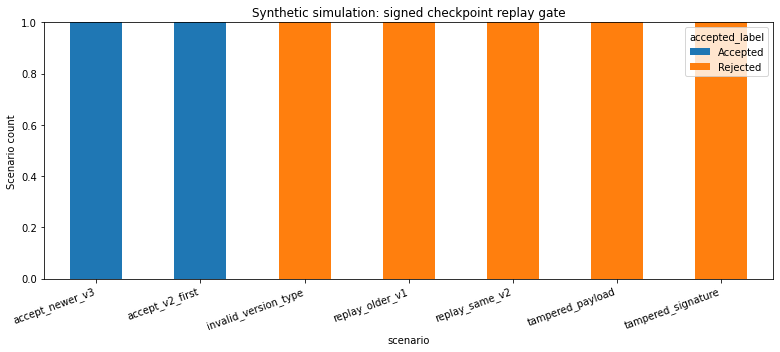

In [7]:
plot_df = results_df.copy()
plot_df["accepted_label"] = plot_df["accepted"].map({True: "Accepted", False: "Rejected"})
counts = plot_df.groupby(["scenario", "accepted_label"]).size().unstack(fill_value=0)
ax = counts.plot(kind="bar", stacked=True, figsize=(11, 5))
ax.set_ylabel("Scenario count")
ax.set_title("Synthetic simulation: signed checkpoint replay gate")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 7. Assertions for the complete scenario run

In [8]:
assert len(results_df) == len(scenario_inputs)
assert results_df["scenario"].is_unique
assert results_df.loc[results_df["scenario"] == "accept_v2_first", "accepted"].iloc[0]
assert not results_df.loc[results_df["scenario"] == "replay_older_v1", "accepted"].iloc[0]
assert not results_df.loc[results_df["scenario"] == "replay_same_v2", "accepted"].iloc[0]
assert results_df.loc[results_df["scenario"] == "accept_newer_v3", "accepted"].iloc[0]
assert not results_df.loc[results_df["scenario"] == "tampered_payload", "accepted"].iloc[0]
assert not results_df.loc[results_df["scenario"] == "tampered_signature", "accepted"].iloc[0]
assert not results_df.loc[results_df["scenario"] == "invalid_version_type", "accepted"].iloc[0]
assert results_df.loc[~results_df["accepted"], "high_water_unchanged_on_rejection"].all()

print("PASS: all scenario-level acceptance expectations hold.")
print("PASS: rejected checkpoints do not advance the high-water mark.")
print("All Lab 02.04 assertions passed.")

PASS: all scenario-level acceptance expectations hold.
PASS: rejected checkpoints do not advance the high-water mark.
All Lab 02.04 assertions passed.


## 8. Export CSV artifacts

In [9]:
results_df.to_csv("trustsr_lab02_04_replay_protection_results.csv", index=False)
print("Generated file:")
print("- trustsr_lab02_04_replay_protection_results.csv")

Generated file:
- trustsr_lab02_04_replay_protection_results.csv


## 9. Interpretation and limitations

### What this synthetic test demonstrates
The implementation accepts a correctly signed checkpoint whose version exceeds the in-memory high-water mark and rejects older/equal versions, invalid signatures, and invalid version types. Rejected inputs do not advance the mark.

### Critical limitations
- The high-water mark is volatile notebook memory; restarting the runtime resets it.
- This implementation is single-threaded. Concurrent acceptance could race without an atomic compare-and-set or transaction.
- A compromised trusted signing key can sign malicious checkpoints.
- Public-key authenticity and rotation/revocation are outside scope.
- Version numbers alone do not prove semantic correctness or dependency-graph completeness.
- This is not a production recovery system, benchmark on real agents, or formal security proof.

### Next step
Lab 02.05 should test concurrent checkpoint submissions and atomic high-water updates, including two versions racing and persistence failures. Keep all results labelled as synthetic simulation.